# Solar mini-grid site suitability: Nigeria

**Question:** *Which unelectrified Nigerian communities are the best candidates for a village-scale solar mini-grid, and how confident can we be in that ranking?*

**Data:** World Bank ESMAP / KTH-dESA OnSSET settlement layer for Nigeria (934,595 cells of 1 km², 2016 release, MIT licence): projected 2030 population, distance to existing and planned grid, distance to roads, solar GHI, urban flag, least-cost technology. Plus geoBoundaries for state and LGA names.

**Method:** H3 hexagons (res. 7, ~5 km²) → eligibility screen → 7 normalised criteria → weighted linear combination → Monte Carlo weight robustness → spatially de-duplicated shortlist → indicative economics → benchmark vs OnSSET-2016.

> Screening analysis. Settlement and grid layers date from 2016, and population is a 2030 projection. Shortlisted sites need field verification.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import pandas as pd
from IPython.display import Image, Markdown, display
from minigrid.mcda import load_hexes, load_criteria, load_weight_scenarios, eligible, score, robustness, shortlist, agreement_with_onsset, Screen
from minigrid.economics import site_economics, portfolio_summary, lcoe_range, load_assumptions
pd.set_option('display.float_format', '{:,.2f}'.format)
h = load_hexes()
print(f"{len(h):,} populated hexagons | {h.pop_2030.sum()/1e6:,.1f} M people (2030) | {h.state.nunique()} states | {h.lga.nunique()} LGAs")
h[['pop_2030', 'grid_km', 'planned_km', 'road_km', 'ghi', 'peak_density', 'urban_share']].describe().T

191,316 populated hexagons | 262.1 M people (2030) | 37 states | 769 LGAs


,count,mean,std,min,25%,50%,75%,max
pop_2030,"191,316.00","1,369.83","7,741.73",1.00,186.00,345.00,709.00,"619,533.00"
grid_km,"191,316.00",52.92,44.50,0.00,18.51,43.08,74.48,224.85
planned_km,"191,316.00",32.97,25.75,0.00,11.30,27.70,50.12,134.44
road_km,"191,316.00",5.41,7.79,0.00,0.86,3.01,6.69,86.05
ghi,"190,914.00","2,145.98",90.03,"1,883.00","2,071.72","2,154.00","2,225.00","2,426.00"
peak_density,"191,316.00",601.23,"2,915.55",1.00,46.00,85.00,214.00,"156,410.00"
urban_share,"191,316.00",0.02,0.10,0.00,0.00,0.00,0.00,1.00


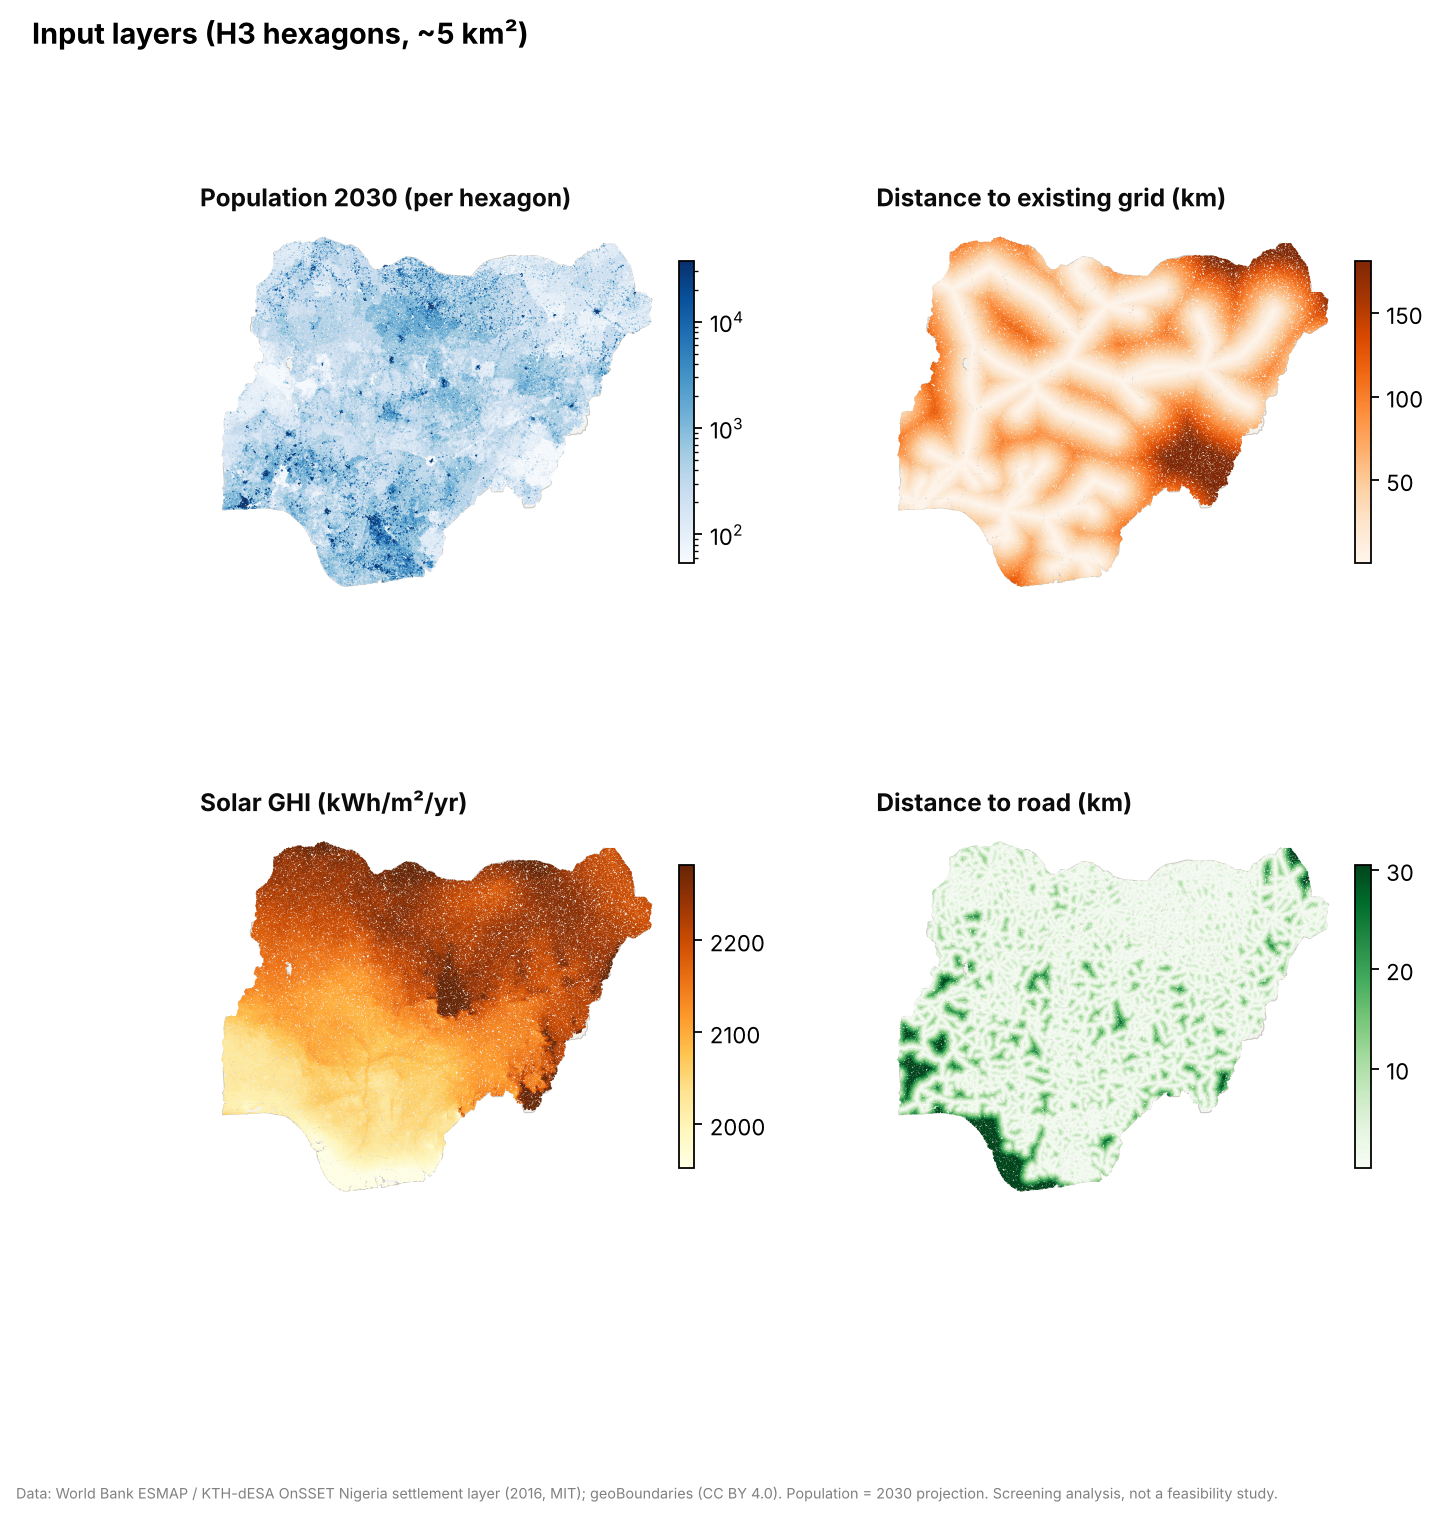

In [2]:
display(Image('../reports/figures/02_criteria_layers.png'))

## 1. Eligibility screen and criteria

In [3]:
s = Screen()
e = eligible(h, s)
print(f"Screen: {s}")
print(f"Eligible: {e.sum():,} hexagons ({h.pop_2030[e].sum()/1e6:,.1f} M people)")
load_criteria()[['criterion', 'column', 'direction', 'transform', 'cap', 'rationale']]

Screen: Screen(min_pop=800, max_pop=10000, max_urban_share=0.5, min_grid_km=5.0)
Eligible: 33,138 hexagons (67.6 M people)


,criterion,column,direction,transform,cap,rationale
0,demand,pop_2030,benefit,log_cap,"4,000.00",More customers spread fixed costs but returns ...
1,compactness,peak_density,benefit,log,NaN,Compact village cores need less distribution n...
2,remoteness,grid_km,benefit,linear_cap,50.00,Far from the grid = grid extension is costly; ...
3,grid_risk,planned_km,benefit,linear_cap,30.00,Lower risk that the main grid arrives and stra...
4,solar,ghi,benefit,minmax,NaN,More energy per installed kWp
5,access,road_km,cost,linear_cap,20.00,Construction logistics and O&M access
6,need,poverty_index,benefit,minmax,NaN,Equity lens: prioritise poorer areas (optional...


## 2. Scores, shortlist and robustness (Balanced weights)

In [4]:
W = load_weight_scenarios()
w = W.loc['Balanced'].drop('description').astype(float).to_dict()
cand = score(h, w)
cand['robust'] = robustness(cand, w, n_draws=1000, top_n=100)
top = site_economics(shortlist(cand, 100))
top[['rank', 'state', 'lga', 'pop_2030', 'grid_km', 'planned_km', 'road_km', 'ghi', 'score', 'robust', 'pv_kwp', 'lcoe_usd_kwh']].head(15)

,rank,state,lga,pop_2030,grid_km,planned_km,road_km,ghi,score,robust,pv_kwp,lcoe_usd_kwh
6919,1,Katsina,Baure,9692,73.85,73.85,0.02,"2,260.00",97.47,1.00,350.49,0.26
10768,2,Katsina,Sandamu,9386,49.53,49.53,0.03,"2,268.60",97.10,1.00,338.00,0.26
10330,3,Katsina,Mai'Adua,8043,53.32,53.32,0.43,"2,286.00",97.06,1.00,287.55,0.26
10929,4,Katsina,Daura,9171,59.07,59.07,0.14,"2,277.00",97.03,1.00,328.98,0.26
10281,5,Katsina,Zango,9966,77.91,77.91,0.08,"2,274.65",96.89,1.00,357.96,0.26
59122,6,Borno,Gwoza,8955,81.36,81.36,0.05,"2,241.75",96.82,1.00,326.53,0.26
35209,7,Zamfara,Birnin Magaji-Kiyaw,8535,53.53,53.53,0.11,"2,251.00",96.73,1.00,309.73,0.26
151514,8,Bauchi,Shira,8861,96.34,96.34,0.07,"2,233.00",96.63,0.99,324.12,0.26
152223,9,Bauchi,Gamawa,9569,71.44,71.44,0.02,"2,216.00",96.61,0.94,352.88,0.26
10755,10,Katsina,Sandamu,7426,58.09,58.09,0.07,"2,277.00",96.54,1.00,266.46,0.26


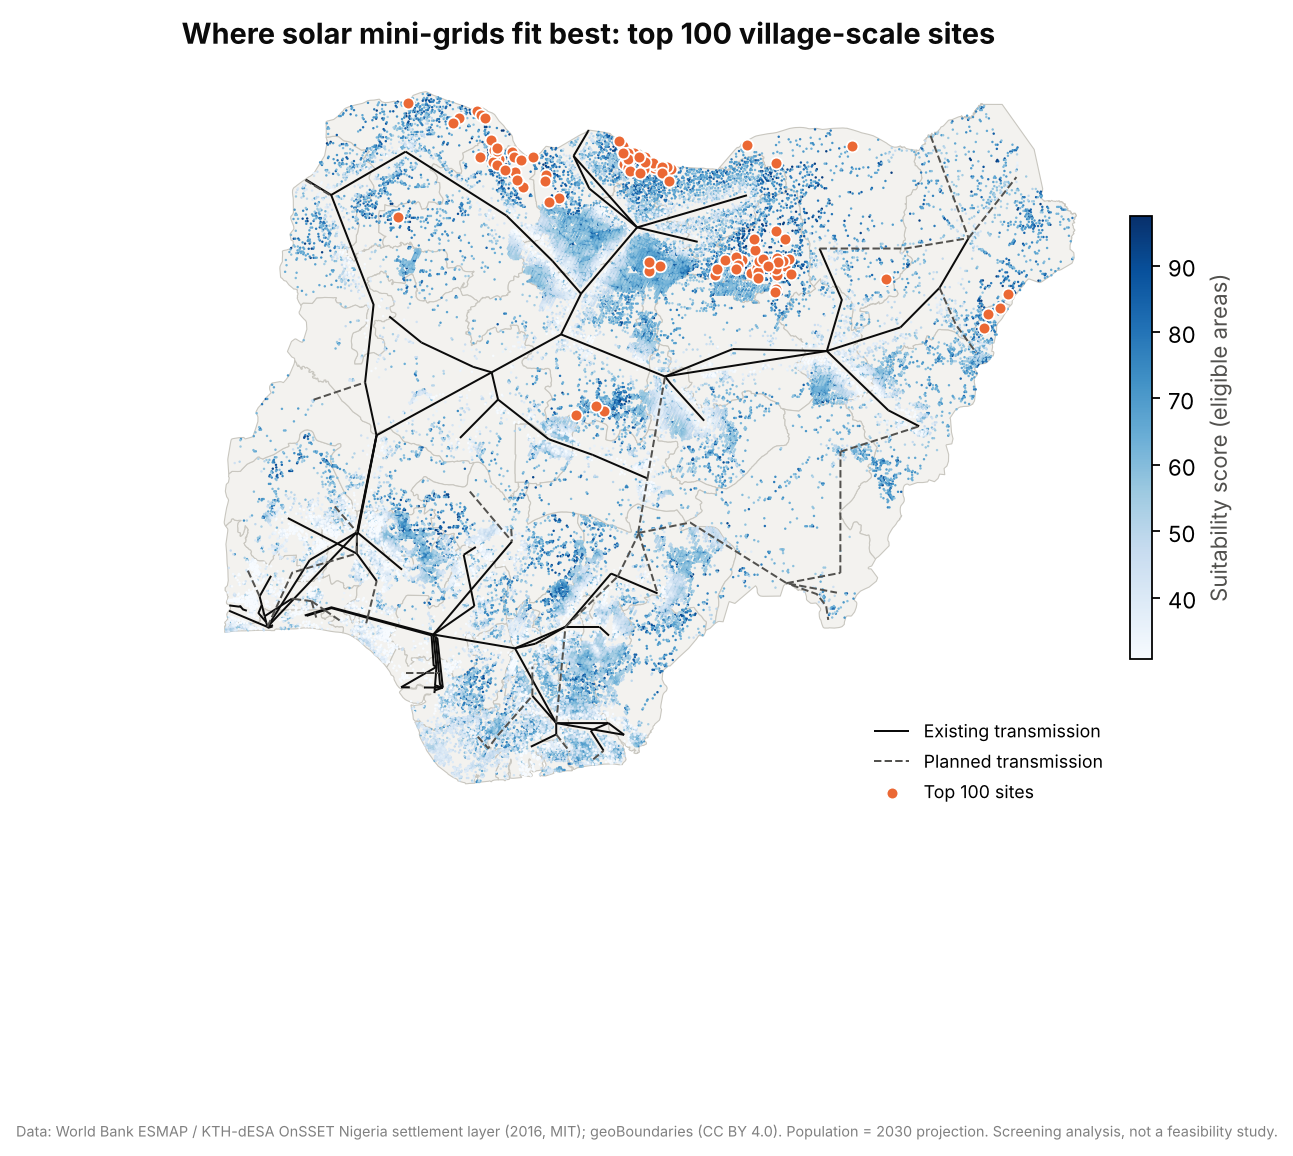

In [5]:
display(Image('../reports/figures/01_suitability_map.png'))

## 3. Do the weights matter?

,Balanced,Developer (commercial),Access & equity
Balanced,100,85,30
Developer (commercial),85,100,26
Access & equity,30,26,100


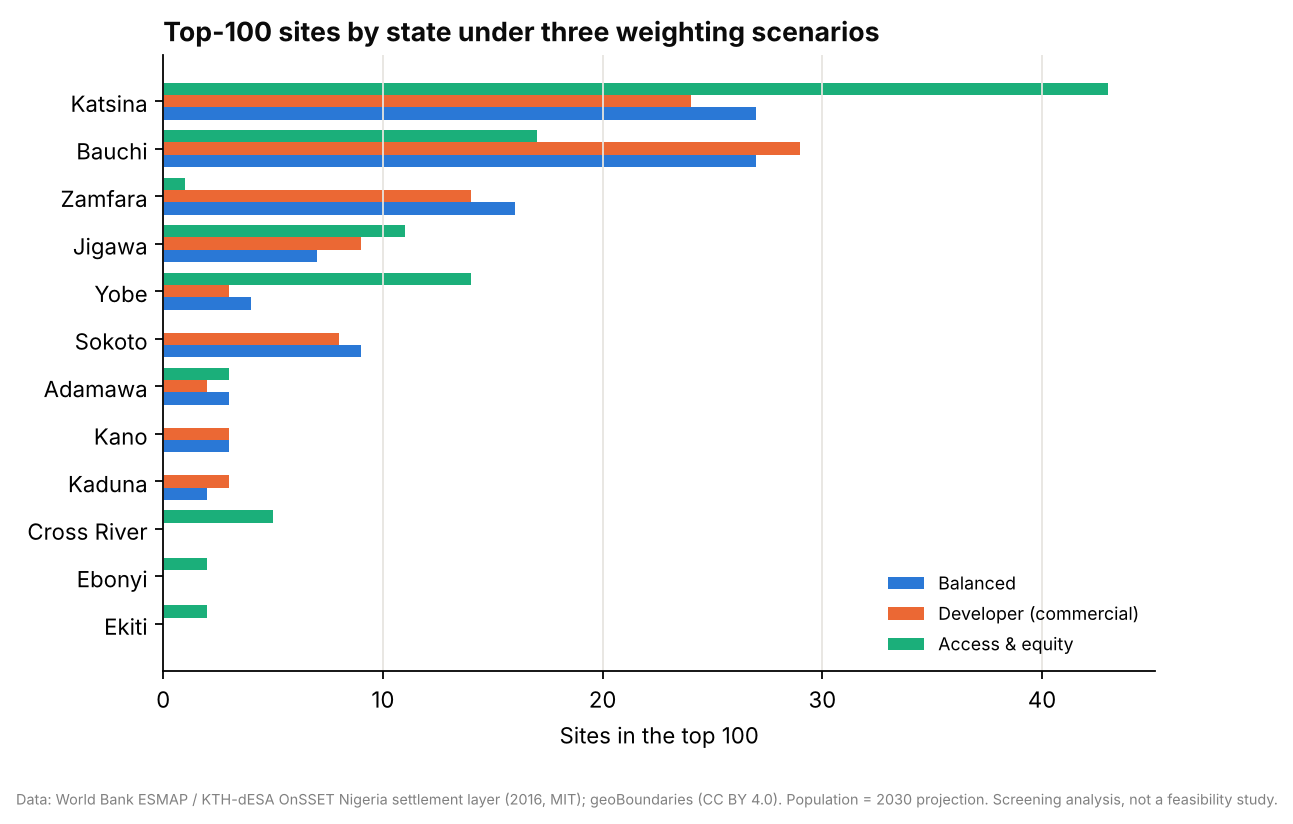

In [6]:
sets = {}
for sc in W.index:
    ww = W.loc[sc].drop('description').astype(float).to_dict()
    sets[sc] = set(shortlist(score(h, ww), 100).h3)
names = list(sets)
overlap = pd.DataFrame([[len(sets[a] & sets[b]) for b in names] for a in names], index=names, columns=names)
display(overlap)
display(Image('../reports/figures/03_scenarios_by_state.png'))

## 4. Indicative economics

sites                   100.00
people              758,632.00
connections          97,978.00
pv_mwp                   27.62
capex_musd               77.24
co2_avoided_kt_yr        37.12
median_lcoe               0.26
median_lcoe_grant         0.18
dtype: float64

,lcoe,lcoe_grant
central,0.26,0.18
low,0.14,0.06
high,0.60,0.48


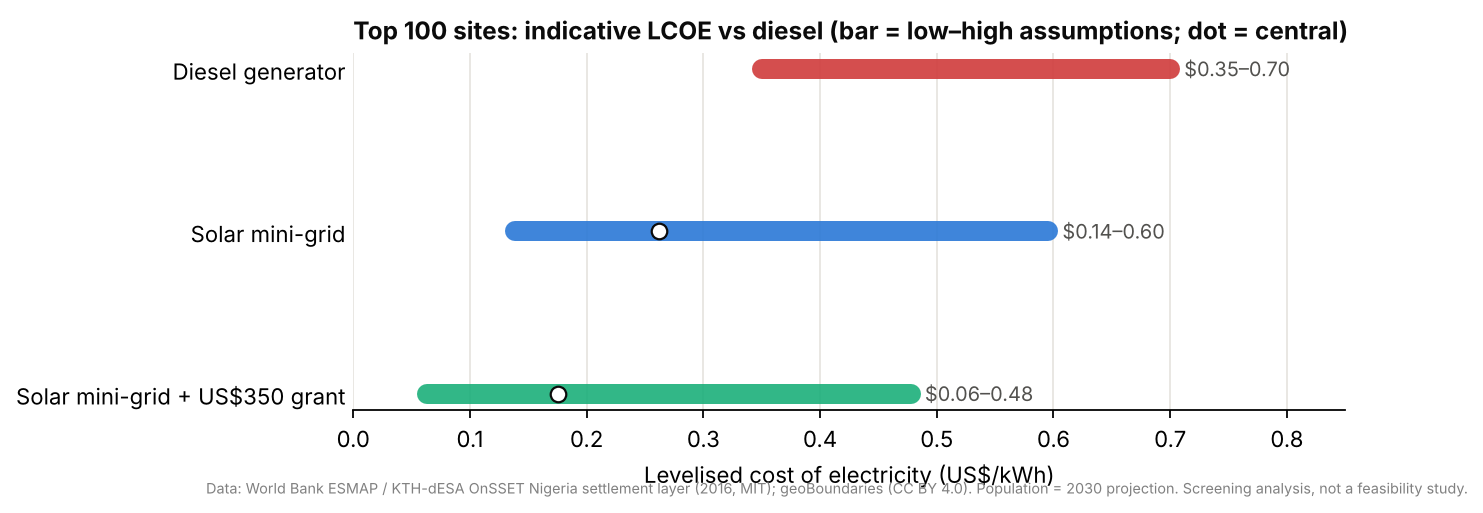

In [7]:
a = load_assumptions(); summ = portfolio_summary(top); rng = lcoe_range(top, a)
display(pd.Series(summ).round(2))
display(pd.DataFrame(rng).T)
display(Image('../reports/figures/05_lcoe_vs_diesel.png'))

## 5. Benchmark vs the World Bank/KTH OnSSET 2016 least-cost model

,sites,onsset_minigrid_share,onsset_minigrid_pop_share
Top shortlist,100.00,0.00,0.00
All eligible,"33,138.00",0.37,0.20


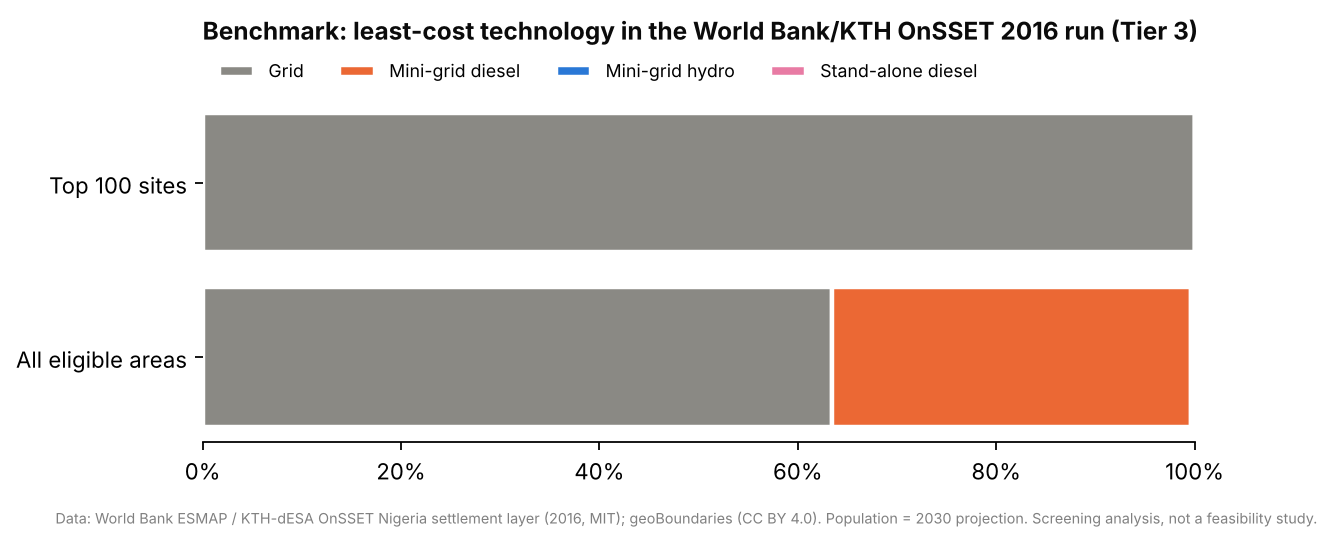

Conservative shortlist (OnSSET-2016 also chose a mini-grid): median population 2,816, median grid distance 73 km, states: {'Borno': 23, 'Yobe': 14, 'Adamawa': 12, 'Plateau': 8}


In [8]:
display(agreement_with_onsset(cand, top))
display(Image('../reports/figures/04_onsset_benchmark.png'))
cons = cand[cand.onsset_tech_code.between(4, 7)].copy()
cons_top = shortlist(cons, 100)
print(f"Conservative shortlist (OnSSET-2016 also chose a mini-grid): median population {cons_top.pop_2030.median():,.0f}, "
      f"median grid distance {cons_top.grid_km.median():,.0f} km, states: {cons_top.state.value_counts().head(4).to_dict()}")

## 6. Findings (generated from the results above)

In [9]:
ts = top.state.value_counts()
Markdown(f'''
1. **{e.sum():,} of {len(h):,} populated hexagons** pass the village-scale screen (800–10,000 people, mostly rural, ≥5 km from the grid).
2. **The best sites cluster in the north-west and north-east.** {", ".join(ts.index[:3])} hold {ts.iloc[:3].sum()/len(top):.0%} of the top {len(top)}:
   compact villages a median **{top.grid_km.median():,.0f} km** from the grid, with GHI around {top.ghi.median():,.0f} kWh/m²/yr.
3. **The shortlist is robust to weights.** {(top.robust >= 0.8).mean():.0%} of sites stay in the top 100 in ≥80% of 1,000 random weight sets,
   and the Balanced and Developer scenarios share {overlap.iloc[0, 1]} of 100 sites. The Access & equity lens shifts the list most.
4. **Indicative economics favour solar.** The top 100 would serve **{summ["people"]/1e6:,.2f} M people** (~{summ["connections"]:,.0f} connections)
   with **{summ["pv_mwp"]:,.1f} MWp** for ~${summ["capex_musd"]:,.0f}M. Central LCOE is **${rng["central"]["lcoe"]:.2f}/kWh**
   (${rng["low"]["lcoe"]:.2f}–{rng["high"]["lcoe"]:.2f}) vs $0.35–0.70 for diesel, and ${rng["central"]["lcoe_grant"]:.2f} with the $350/connection grant.
   That avoids ~**{summ["co2_avoided_kt_yr"]:,.0f} kt CO₂/yr** if diesel gensets were the alternative.
5. **OnSSET-2016 disagrees, for a known reason.** It chose grid extension for all 100 sites. Its 2016 PV/battery costs made solar mini-grids
   least-cost for ~0.1% of the population, and its mini-grids were small diesel systems. Newer modelling (SEforALL Nigeria IEP, 2022)
   finds mini-grids least-cost in denser settlements far from the grid, which is this shortlist's profile. A conservative shortlist of sites both models agree on is provided.
6. **Next step:** field-verify the top sites for current grid status (the grid has expanded since 2016), demand, anchor loads and willingness to pay.
''')


1. **33,138 of 191,316 populated hexagons** pass the village-scale screen (800–10,000 people, mostly rural, ≥5 km from the grid).
2. **The best sites cluster in the north-west and north-east.** Katsina, Bauchi, Zamfara hold 70% of the top 100:
   compact villages a median **69 km** from the grid, with GHI around 2,242 kWh/m²/yr.
3. **The shortlist is robust to weights.** 60% of sites stay in the top 100 in ≥80% of 1,000 random weight sets,
   and the Balanced and Developer scenarios share 85 of 100 sites. The Access & equity lens shifts the list most.
4. **Indicative economics favour solar.** The top 100 would serve **0.76 M people** (~97,978 connections)
   with **27.6 MWp** for ~$77M. Central LCOE is **$0.26/kWh**
   ($0.14–0.60) vs $0.35–0.70 for diesel, and $0.18 with the $350/connection grant.
   That avoids ~**37 kt CO₂/yr** if diesel gensets were the alternative.
5. **OnSSET-2016 disagrees, for a known reason.** It chose grid extension for all 100 sites. Its 2016 PV/battery costs made solar mini-grids
   least-cost for ~0.1% of the population, and its mini-grids were small diesel systems. Newer modelling (SEforALL Nigeria IEP, 2022)
   finds mini-grids least-cost in denser settlements far from the grid, which is this shortlist's profile. A conservative shortlist of sites both models agree on is provided.
6. **Next step:** field-verify the top sites for current grid status (the grid has expanded since 2016), demand, anchor loads and willingness to pay.
